In [1]:
# Colab already includes most of these packages.
!pip install -q pandas pillow matplotlib requests torchvision

import io
import random
from pathlib import Path

import pandas as pd
import requests
import matplotlib.pyplot as plt
import torchvision.transforms.functional as TF

from PIL import Image

In [2]:
from google.colab import files

# Upload the finalized SciQuality Stage1_train.csv file.
uploaded = files.upload()
csv_name = next(iter(uploaded))

labels = pd.read_csv(io.BytesIO(uploaded[csv_name]))
print(labels.shape)
labels.head()

Saving Stage1_train.csv to Stage1_train.csv
(46638, 2)


,label,goes_class
0,2010/12/06/HMI.m2010.12.06_07.00.00.jpg,0
1,2010/12/06/HMI.m2010.12.06_08.00.00.jpg,0
2,2010/12/06/HMI.m2010.12.06_09.00.00.jpg,0
3,2010/12/06/HMI.m2010.12.06_10.00.00.jpg,0
4,2010/12/06/HMI.m2010.12.06_11.00.00.jpg,0


In [3]:
# Extract timestamps and inspect distribution
# Recover the observation timestamp from each image path.
timestamp_text = labels["label"].str.extract(
    r"HMI\.m(\d{4}\.\d{2}\.\d{2}_\d{2}\.\d{2}\.\d{2})"
)[0]

labels["timestamp"] = pd.to_datetime(
    timestamp_text,
    format="%Y.%m.%d_%H.%M.%S",
)

labels["year"] = labels["timestamp"].dt.year
labels["class_name"] = labels["goes_class"].map({0: "NF", 1: "FL"})

pd.crosstab(labels["year"], labels["class_name"])

class_name,FL,NF
year,,
2010,0,562
2011,1595,4933
2012,1619,4897
2013,1959,5697
2014,3522,4883
2015,2235,6276
2016,401,7936
2017,0,123


In [4]:
# Select one NF and one FL image from different Stage 1 years.
target_years = [2011, 2014, 2017]
selected = []

for year in target_years:
    for label in [0, 1]:
        candidates = labels[
            (labels["year"] == year) &
            (labels["goes_class"] == label)
        ]

        if not candidates.empty:
            selected.append(
                candidates.sample(1, random_state=year + label)
            )

selected = pd.concat(selected, ignore_index=True)
selected[["label", "timestamp", "class_name"]]

,label,timestamp,class_name
0,2011/03/27/HMI.m2011.03.27_23.00.00.jpg,2011-03-27 23:00:00,NF
1,2011/02/20/HMI.m2011.02.20_17.00.00.jpg,2011-02-20 17:00:00,FL
2,2014/09/14/HMI.m2014.09.14_14.00.00.jpg,2014-09-14 14:00:00,NF
3,2014/10/25/HMI.m2014.10.25_07.00.00.jpg,2014-10-25 07:00:00,FL
4,2017/01/05/HMI.m2017.01.05_21.00.00.jpg,2017-01-05 21:00:00,NF


In [5]:
SOURCE_ID = 19  # HMI magnetogram source in Helioviewer


def download_hmi_image(timestamp):
    """Download the HMI image closest to the requested observation time."""
    date = timestamp.strftime("%Y-%m-%dT%H:%M:%SZ")

    response = requests.get(
        "https://api.helioviewer.org/v2/getJP2Image/",
        params={
            "date": date,
            "sourceId": SOURCE_ID,
        },
        timeout=90,
    )
    response.raise_for_status()

    # Decode the downloaded JPEG-2000 image as grayscale.
    return Image.open(io.BytesIO(response.content)).convert("L")


images = []

for row in selected.itertuples():
    try:
        image = download_hmi_image(row.timestamp)

        images.append({
            "image": image,
            "timestamp": row.timestamp,
            "class_name": row.class_name,
        })

        print(
            f"Downloaded {row.timestamp} | "
            f"{row.class_name} | original size={image.size}"
        )

    except Exception as error:
        print(f"Could not download {row.timestamp}: {error}")

Downloaded 2011-03-27 23:00:00 | NF | original size=(4096, 4096)
Downloaded 2011-02-20 17:00:00 | FL | original size=(4096, 4096)
Downloaded 2014-09-14 14:00:00 | NF | original size=(4096, 4096)
Downloaded 2014-10-25 07:00:00 | FL | original size=(4096, 4096)
Downloaded 2017-01-05 21:00:00 | NF | original size=(4096, 4096)


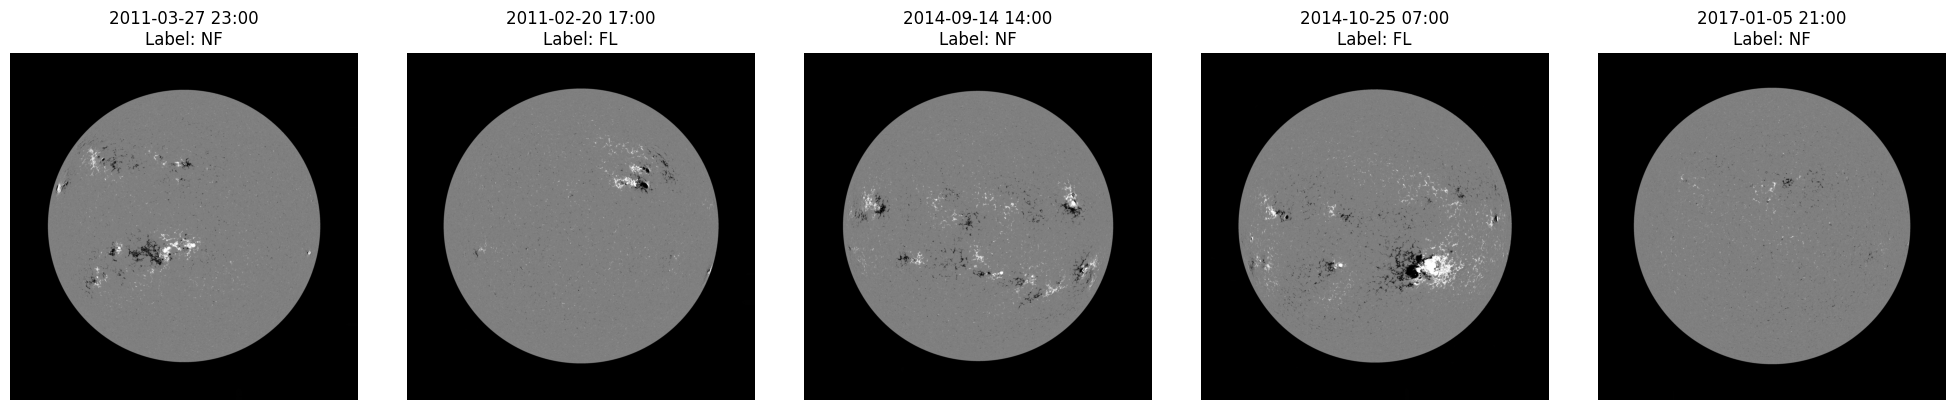

In [6]:
fig, axes = plt.subplots(
    1,
    len(images),
    figsize=(4 * len(images), 4),
)

if len(images) == 1:
    axes = [axes]

for axis, item in zip(axes, images):
    axis.imshow(item["image"], cmap="gray")
    axis.set_title(
        f"{item['timestamp']:%Y-%m-%d %H:%M}\n"
        f"Label: {item['class_name']}"
    )
    axis.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Define the current project augmentations
IMAGE_SIZE = 512
ROTATION_DEGREES = 5


def apply_augmentation(image, augmentation, angle=None):
    """Apply the same transformations currently used by the project."""

    # Resize before augmentation, matching the training transform order.
    image = TF.resize(
        image,
        [IMAGE_SIZE, IMAGE_SIZE],
        antialias=True,
    )

    if augmentation == "horizontal_flip":
        image = TF.hflip(image)

    elif augmentation == "vertical_flip":
        image = TF.vflip(image)

    elif augmentation == "rotation_180":
        image = TF.vflip(TF.hflip(image))

    elif augmentation == "small_rotation":
        if angle is None:
            angle = random.uniform(
                -ROTATION_DEGREES,
                ROTATION_DEGREES,
            )
        image = TF.rotate(image, angle, fill=0)

    elif augmentation != "original":
        raise ValueError(f"Unknown augmentation: {augmentation}")

    return image

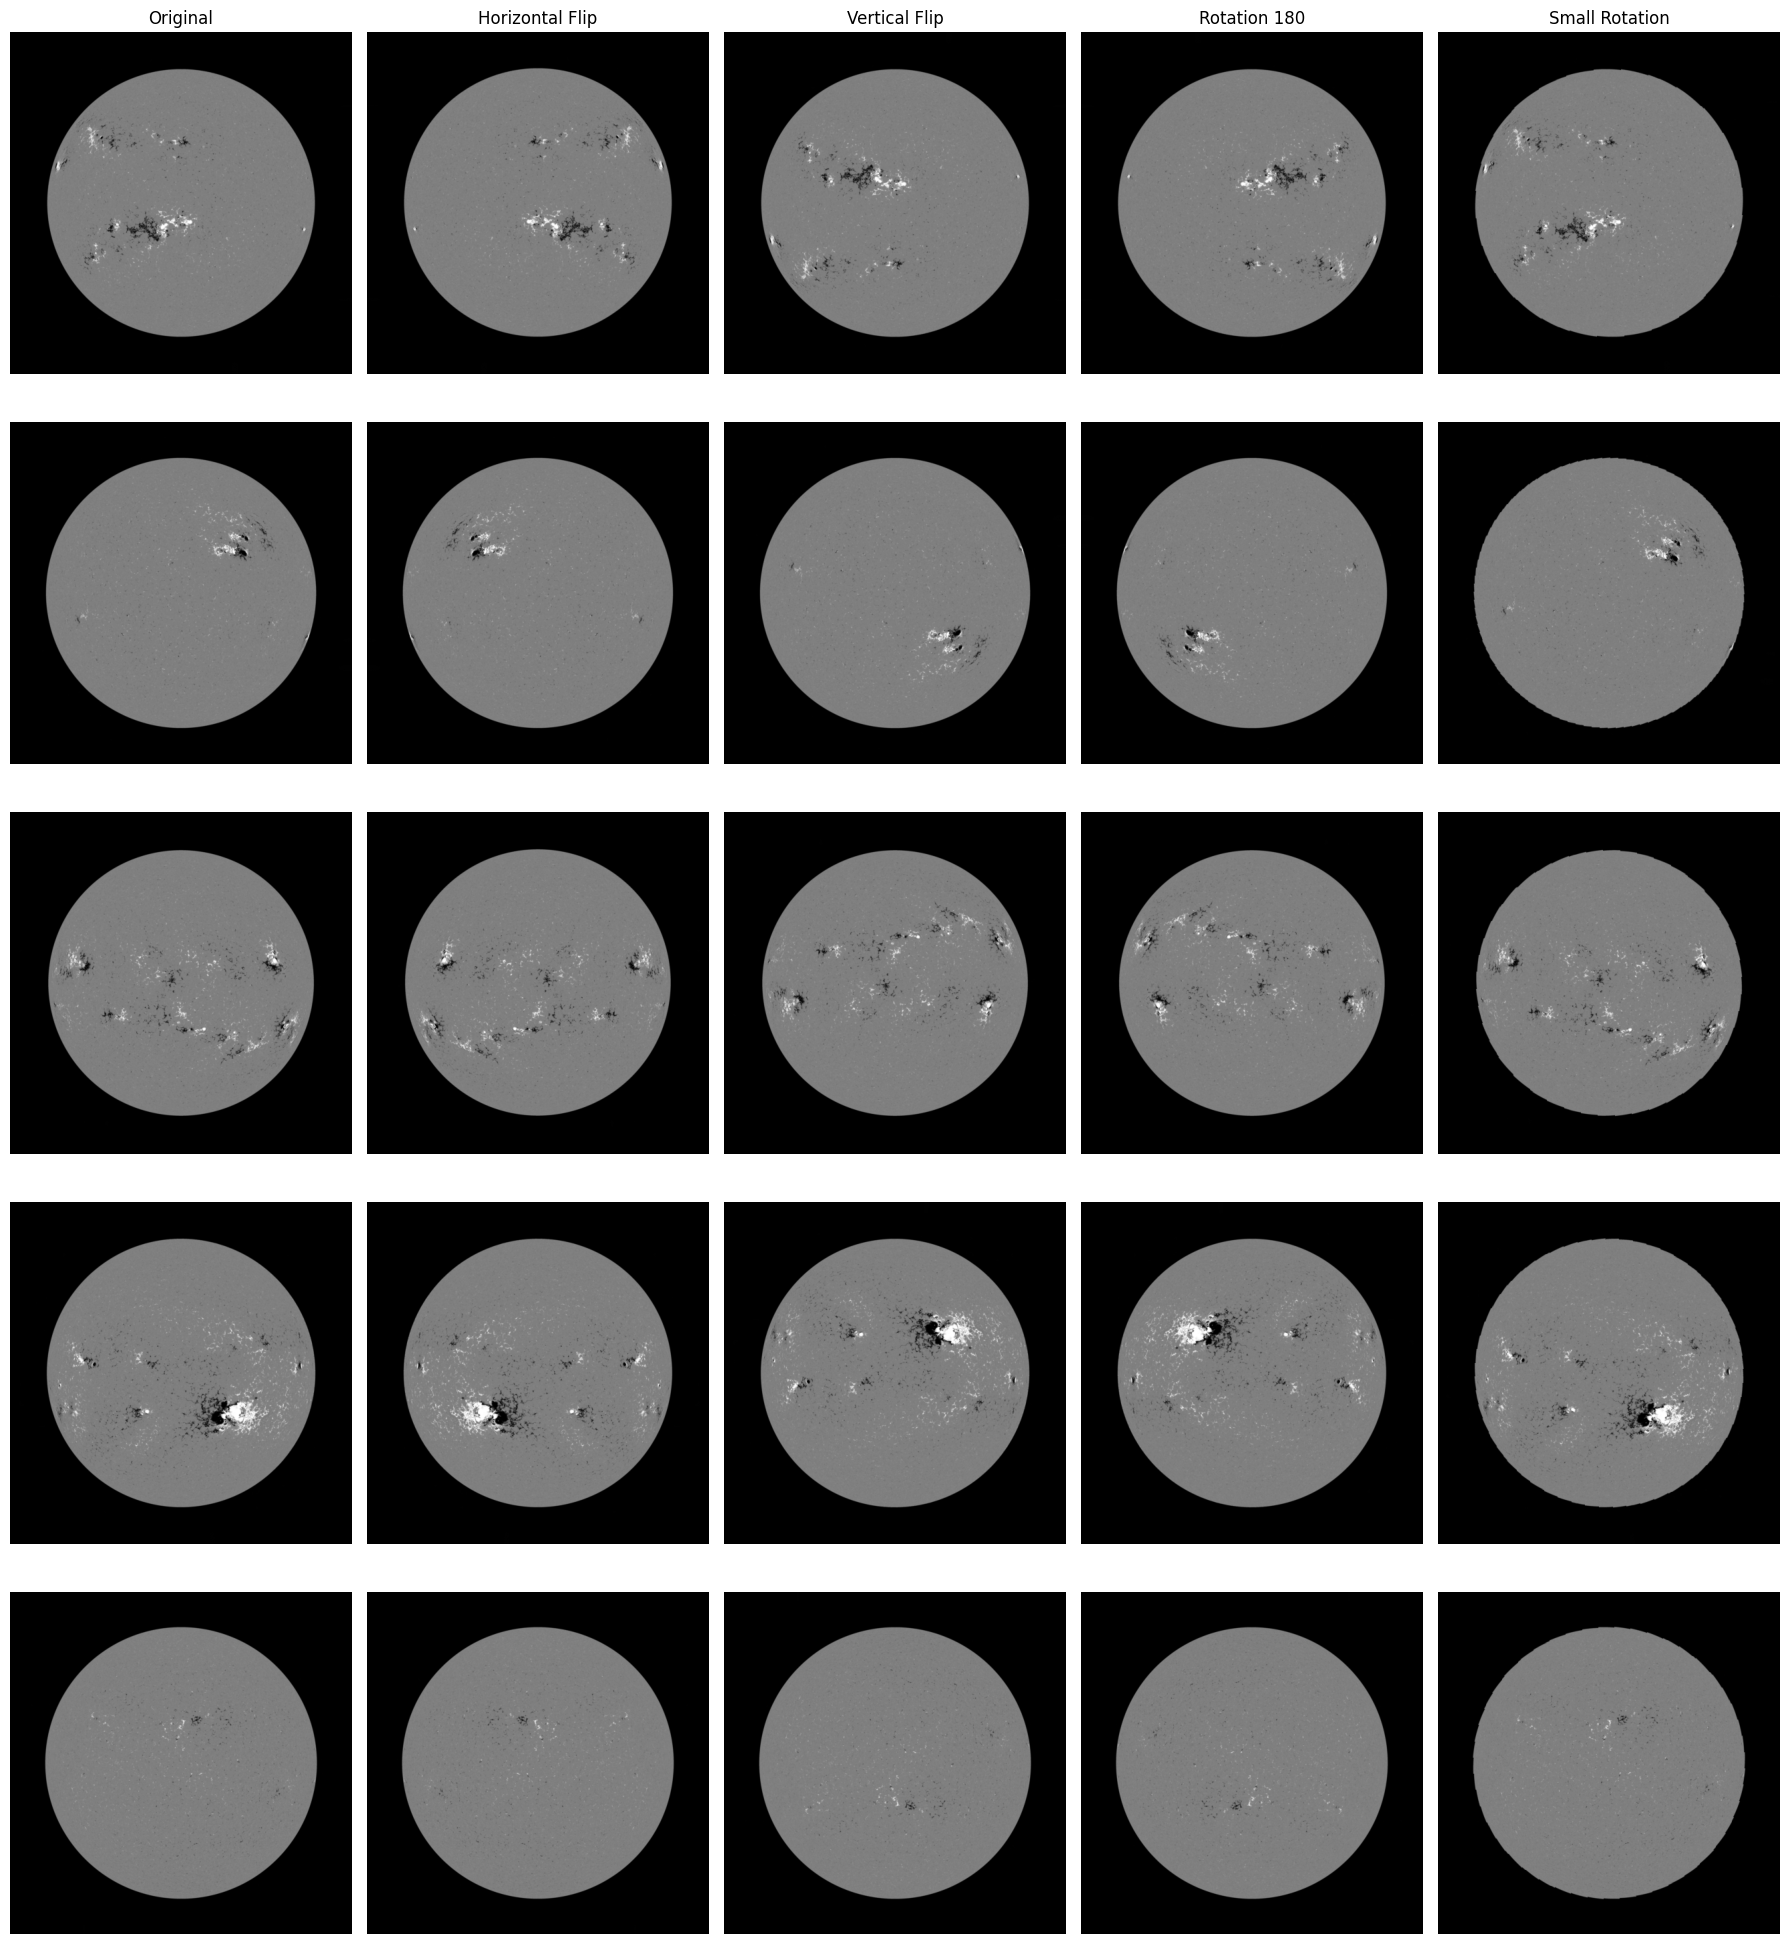

In [8]:
# Display all augmentations for every image
augmentations = [
    "original",
    "horizontal_flip",
    "vertical_flip",
    "rotation_180",
    "small_rotation",
]

# Fixed seed makes the random rotations reproducible.
random.seed(42)

fig, axes = plt.subplots(
    len(images),
    len(augmentations),
    figsize=(18, 4 * len(images)),
)

if len(images) == 1:
    axes = [axes]

for row_index, item in enumerate(images):
    for column_index, augmentation in enumerate(augmentations):
        transformed = apply_augmentation(
            item["image"],
            augmentation,
        )

        axes[row_index][column_index].imshow(
            transformed,
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        if row_index == 0:
            axes[row_index][column_index].set_title(
                augmentation.replace("_", " ").title()
            )

        if column_index == 0:
            axes[row_index][column_index].set_ylabel(
                f"{item['timestamp']:%Y-%m-%d}\n"
                f"{item['class_name']}"
            )

        axes[row_index][column_index].axis("off")

plt.tight_layout()
plt.show()

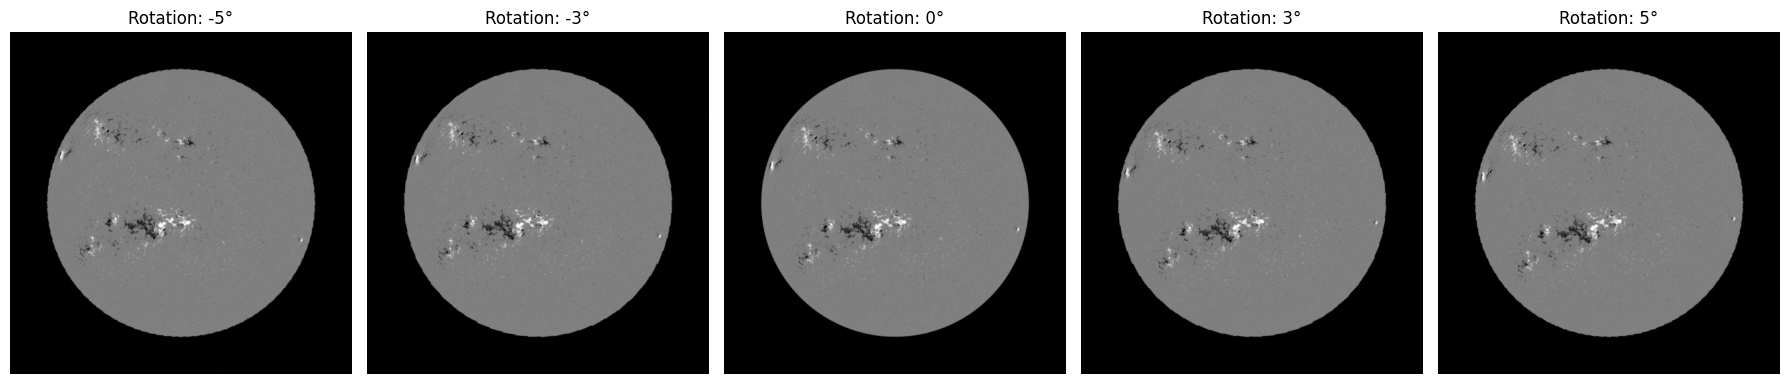

In [9]:
# Examine small rotations more carefully
# Display fixed angles to inspect cropping and artificial borders.
angles = [-5, -3, 0, 3, 5]
example = images[0]

fig, axes = plt.subplots(1, len(angles), figsize=(18, 4))

for axis, angle in zip(axes, angles):
    rotated = apply_augmentation(
        example["image"],
        "small_rotation",
        angle=angle,
    )

    axis.imshow(rotated, cmap="gray", vmin=0, vmax=255)
    axis.set_title(f"Rotation: {angle}°")
    axis.axis("off")

plt.tight_layout()
plt.show()